# Laboratory 05. Calibrate, mask and measure

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

This is a complete worked laboratory. Run every cell in order, then carry out the investigations. The default data are synthetic. Consult the matching lecture and [assessment brief](../ASSESSMENT.md).

In [1]:
# Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
from pathlib import Path
import sys, subprocess
# Local runs discover the checkout. Colab fetches it only if it is absent.
roots = [Path.cwd(), *Path.cwd().parents, Path('/content/satellitedatahscourse')]
root = next((p for p in roots if (p/'python'/'eo_course.py').exists()), None)
if root is None:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Open this notebook inside the course repository.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'requests', 'rasterio', 'scikit-learn'], check=True)
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/caribbeanai/satellitedatahscourse.git', '/content/satellitedatahscourse'], check=True)
    root = Path('/content/satellitedatahscourse')
sys.path.insert(0, str(root/'python'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eo_course as eo
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.facecolor': 'white'})
print(eo.CREDIT)
print('Default data: SYNTHETIC teaching examples, not observations of Jamaica.')


Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
Default data: SYNTHETIC teaching examples, not observations of Jamaica.


## 1. Check the calibration by hand
 A stored number must be calibrated using its asset metadata, with nodata removed first. These invented values demonstrate why an offset matters. A ratio does not generally cancel an additive offset. See S1 and S2 in the source register.

In [2]:
dn_red = np.array([2000., 0., 3500.])
dn_nir = np.array([6000., 0., 5500.])
red = eo.reflectance(dn_red, scale=.0001, offset=-.1)
nir = eo.reflectance(dn_nir, scale=.0001, offset=-.1)
calibrated = eo.normalized_difference(nir, red)
naive = eo.normalized_difference(dn_nir, dn_red)
display(pd.DataFrame({'red_reflectance':red, 'nir_reflectance':nir,
                      'calibrated_ndvi':calibrated, 'raw_number_ratio':naive}))
assert np.isclose(calibrated[0], 2/3)
assert np.isnan(calibrated[1])

   red_reflectance  nir_reflectance  calibrated_ndvi  raw_number_ratio
0             0.10             0.50         0.666667          0.500000
1              NaN              NaN              NaN               NaN
2             0.25             0.45         0.285714          0.222222

## 2. Invent six satellite visits
 The cloud pattern, reflectances and ground pattern below are generated by code. No pixel came from a satellite. A small upper-left square is never observed; it must remain unknown.

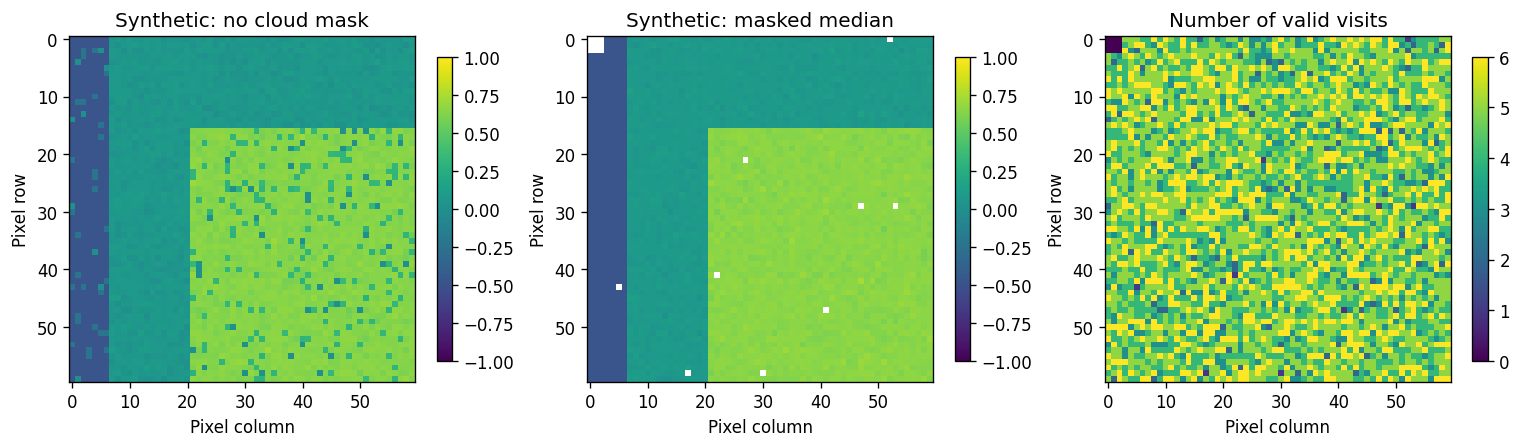

In [3]:
scene = eo.synthetic_scene(seed=42)
index_stack = eo.normalized_difference(scene['nir'], scene['red'])
valid = eo.clear_mask(scene['scl'])
unmasked = np.median(index_stack, axis=0)
masked, count = eo.median_composite(index_stack, valid, min_observations=2)
fig, axes = plt.subplots(1,3,figsize=(13,4))
for ax, image, title in zip(axes, [unmasked, masked, count],
                            ['Synthetic: no cloud mask','Synthetic: masked median','Number of valid visits']):
    im=ax.imshow(image, vmin=0 if title.startswith('Number') else -1, vmax=6 if title.startswith('Number') else 1); ax.set_title(title); ax.set_xlabel('Pixel column'); ax.set_ylabel('Pixel row'); fig.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout(); plt.show()
assert np.isnan(masked[:3,:3]).all()

## 3. Investigate the support rule
 **Your task:** compare one, two and four required observations. Is the fraction above 0.4 stable? Keep unknown hectares separate from observed pixels below the threshold. The 20 m grid is a teaching assumption.

In [4]:
rows=[]
for minimum in [1,2,4]:
    image, support = eo.median_composite(index_stack,valid,minimum)
    observed=np.isfinite(image)
    rows.append({'minimum_visits':minimum, 'observed_ha':observed.sum()*.04,
                 'unknown_ha':(~observed).sum()*.04,
                 'candidate_vegetation_ha':((image>.4)&observed).sum()*.04,
                 'candidate_fraction_observed':float((image[observed]>.4).mean())})
quality_table=pd.DataFrame(rows)
display(quality_table)
assert quality_table.observed_ha.is_monotonic_decreasing

   minimum_visits  ...  candidate_fraction_observed
0               1  ...                     0.477861
1               2  ...                     0.477387
2               4  ...                     0.475363

[3 rows x 5 columns]

## 4. Optional live Sentinel-2 experiment
 Set `RUN_LIVE=True` only when you want a network request. This searches a small Kingston rectangle, saves returned metadata and reads one scene on a projected grid. The candidate with lowest tile cloud percentage may still be cloudy over the rectangle. Inspect its support before interpreting it. One acquisition is not a composite. A failed request stops the experiment; no simulated observations are substituted.

In [5]:
RUN_LIVE=False
if RUN_LIVE:
    import json
    bbox=[-76.82,17.98,-76.81,17.99]
    items=eo.search_sentinel(bbox,'2025-01-01','2025-02-28')
    if not items:
        raise RuntimeError('No scenes returned. Change the documented search window.')
    item=min(items,key=lambda x:x['properties'].get('eo:cloud_cover',100))
    live=eo.read_sentinel_pair(item,bbox,metres=20)
    out=root/'outputs'/'week1_live';out.mkdir(parents=True,exist_ok=True)
    (out/'scene.json').write_text(json.dumps(item,indent=2))
    np.save(out/'ndvi.npy',live['ndvi'])
    eo.write_manifest(out/'manifest.json','observed',
        {'item_id':item['id'],'datetime':item['properties']['datetime']},
        {'bbox':bbox,'metres':20,'crs':live['crs'],'scl_accepted':[4,5,6]},
        [out/'scene.json',out/'ndvi.npy'])
    plt.imshow(live['ndvi'],vmin=-1,vmax=1,cmap='RdYlGn')
    plt.title('Observed Sentinel-2 NDVI: '+item['id']);plt.colorbar();plt.show()
else:
    print('Live retrieval skipped. All preceding results remain synthetic.')

Live retrieval skipped. All preceding results remain synthetic.


## 5. Write the data card
 Record your question, boundary, product/scene IDs, calibration, grid, quality classes, date window, support rule, observed/unknown area and permitted use. Explain why the median of NDVI need not equal NDVI computed from separate median bands. Extend the experiment by varying cloud frequency in a modified copy of `synthetic_scene`; keep your changed function with the submission.

## Before submitting

Restart the kernel and run all cells. Label synthetic and observed outputs separately. Include the source, dates, units, quality policy and unknown coverage in captions. See [verified sources](../SOURCES.md) and the [instructor guide](../instructor/GUIDE.md).

Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.